# 50 Startups — 多元線性回歸 (scikit-learn)

目標：用 `R&D Spend`、`Administration`、`Marketing Spend`、`State` 預測 `Profit`。

流程：
1. 載入資料與探索
2. 前處理（State 類別變數 One-Hot 編碼）
3. 切分訓練 / 測試集
4. 建立 `LinearRegression` 多元線性回歸模型
5. 評估（R²、MAE、RMSE）
6. 使用 matplotlib 視覺化

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.unicode_minus'] = False

## 1. 載入資料

In [ ]:
URL = ("https://gist.githubusercontent.com/GaneshSparkz/b5662effbdae8746f7f7d8ed70c42b2d/raw/"
       "faf8b1a0d58e251f48a647d3881e7a960c3f0925/50_Startups.csv")

try:
    df = pd.read_csv(URL)
except Exception as e:
    # 若無法連網，改讀同目錄下的本地檔案
    print("線上讀取失敗，改用本地檔案：", e)
    df = pd.read_csv("50_Startups.csv")

print(df.shape)
df.head()

(50, 5)


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [ ]:
df.isnull().sum()

,0
R&D Spend,0
Administration,0
Marketing Spend,0
State,0
Profit,0


## 2. 探索性分析：各特徵與 Profit 的關係

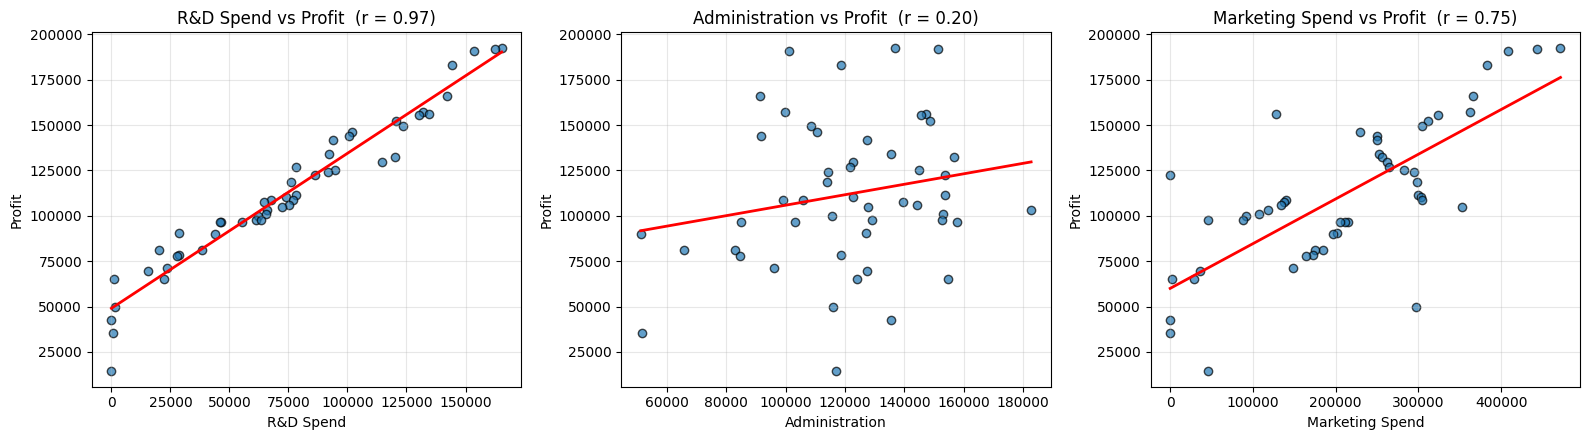

In [ ]:
num_cols = ['R&D Spend', 'Administration', 'Marketing Spend']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, num_cols):
    ax.scatter(df[col], df['Profit'], alpha=0.7, edgecolor='k')
    # 簡單一次趨勢線
    m, b = np.polyfit(df[col], df['Profit'], 1)
    xs = np.linspace(df[col].min(), df[col].max(), 100)
    ax.plot(xs, m * xs + b, color='red', linewidth=2)
    ax.set_xlabel(col)
    ax.set_ylabel('Profit')
    ax.set_title(f'{col} vs Profit  (r = {df[col].corr(df["Profit"]):.2f})')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

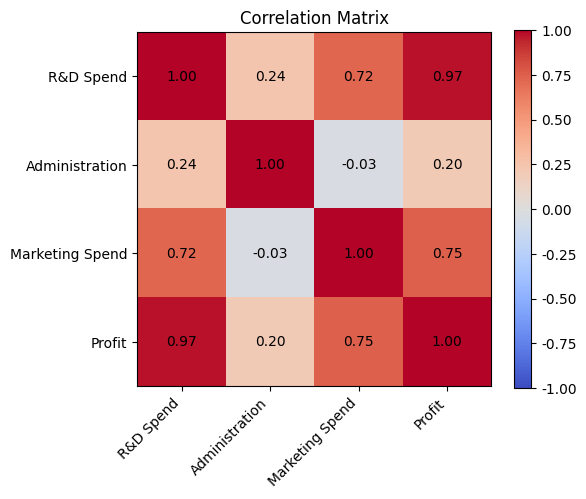

In [ ]:
corr = df[num_cols + ['Profit']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im)
ax.set_title('Correlation Matrix')
plt.tight_layout()
plt.show()

## 3. 前處理與切分資料
`State` 為類別變數，使用 One-Hot 編碼並 `drop='first'` 避免虛擬變數陷阱 (dummy variable trap)。

In [ ]:
X = df.drop(columns='Profit')
y = df['Profit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (40, 4)  Test: (10, 4)


## 4. 建立多元線性回歸模型

In [ ]:
preprocess = ColumnTransformer(
    transformers=[('state', OneHotEncoder(drop='first'), ['State'])],
    remainder='passthrough')

model = Pipeline([
    ('preprocess', preprocess),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

# 回歸係數
feature_names = model.named_steps['preprocess'].get_feature_names_out()
reg = model.named_steps['regressor']
coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': reg.coef_})
print('Intercept:', round(reg.intercept_, 2))
coef_df

Intercept: 42554.17


,Feature,Coefficient
0,state__State_Florida,-959.284160
1,state__State_New York,699.369053
2,remainder__R&D Spend,0.773467
3,remainder__Administration,0.032885
4,remainder__Marketing Spend,0.036610


## 5. 模型評估

In [ ]:
y_pred_train = model.predict(X_train)
y_pred = model.predict(X_test)

def report(y_true, y_hat, name):
    print(f'[{name}]  R² = {r2_score(y_true, y_hat):.4f}  |  '
          f'MAE = {mean_absolute_error(y_true, y_hat):,.2f}  |  '
          f'RMSE = {np.sqrt(mean_squared_error(y_true, y_hat)):,.2f}')

report(y_train, y_pred_train, 'Train')
report(y_test, y_pred, 'Test ')

result = pd.DataFrame({'Actual': y_test.values,
                       'Predicted': y_pred.round(2),
                       'Error': (y_test.values - y_pred).round(2)})
result

[Train]  R² = 0.9502  |  MAE = 6,341.54  |  RMSE = 9,031.67
[Test ]  R² = 0.9347  |  MAE = 7,514.29  |  RMSE = 9,137.99


,Actual,Predicted,Error
0,103282.38,103015.20,267.18
1,144259.40,132582.28,11677.12
2,146121.95,132447.74,13674.21
3,77798.83,71976.10,5822.73
4,191050.39,178537.48,12512.91
5,105008.31,116161.24,-11152.93
6,81229.06,67851.69,13377.37
7,97483.56,98791.73,-1308.17
8,110352.25,113969.44,-3617.19
9,166187.94,167921.07,-1733.13


## 6. 視覺化結果

### 6.1 實際值 vs 預測值

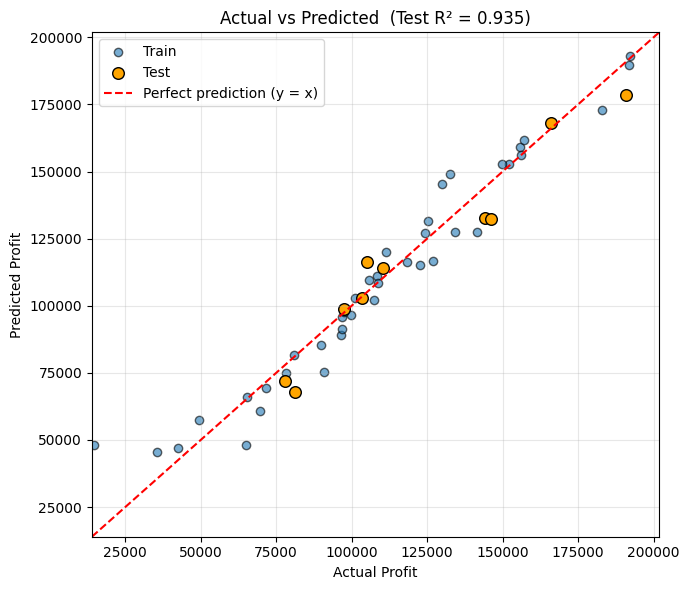

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_train, y_pred_train, label='Train', alpha=0.6, edgecolor='k')
ax.scatter(y_test, y_pred, label='Test', color='orange', s=70, edgecolor='k')
lims = [min(y.min(), y_pred.min()) * 0.95, max(y.max(), y_pred.max()) * 1.05]
ax.plot(lims, lims, 'r--', label='Perfect prediction (y = x)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual Profit'); ax.set_ylabel('Predicted Profit')
ax.set_title(f'Actual vs Predicted  (Test R² = {r2_score(y_test, y_pred):.3f})')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 測試集：實際值與預測值曲線比較

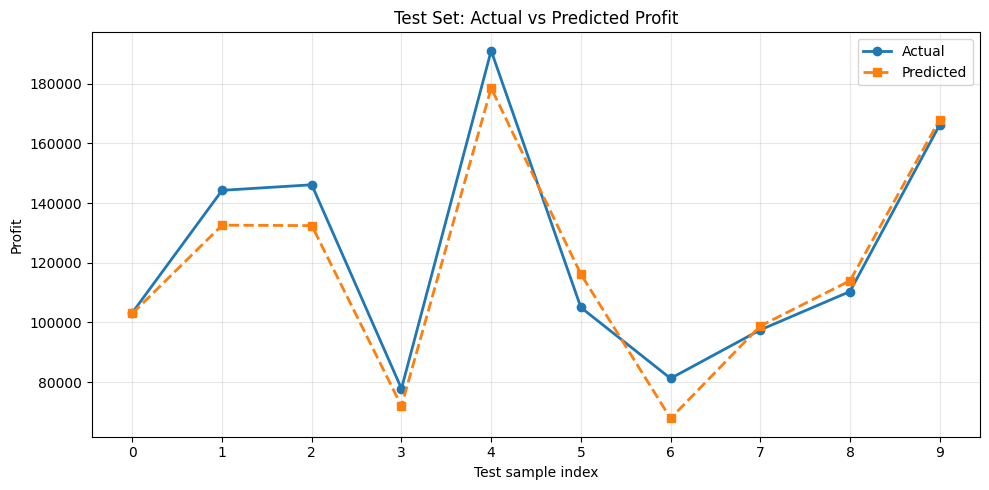

In [ ]:
idx = np.arange(len(y_test))
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(idx, y_test.values, 'o-', label='Actual', linewidth=2)
ax.plot(idx, y_pred, 's--', label='Predicted', linewidth=2)
ax.set_xticks(idx)
ax.set_xlabel('Test sample index'); ax.set_ylabel('Profit')
ax.set_title('Test Set: Actual vs Predicted Profit')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.3 全部資料：依實際 Profit 排序後的擬合曲線

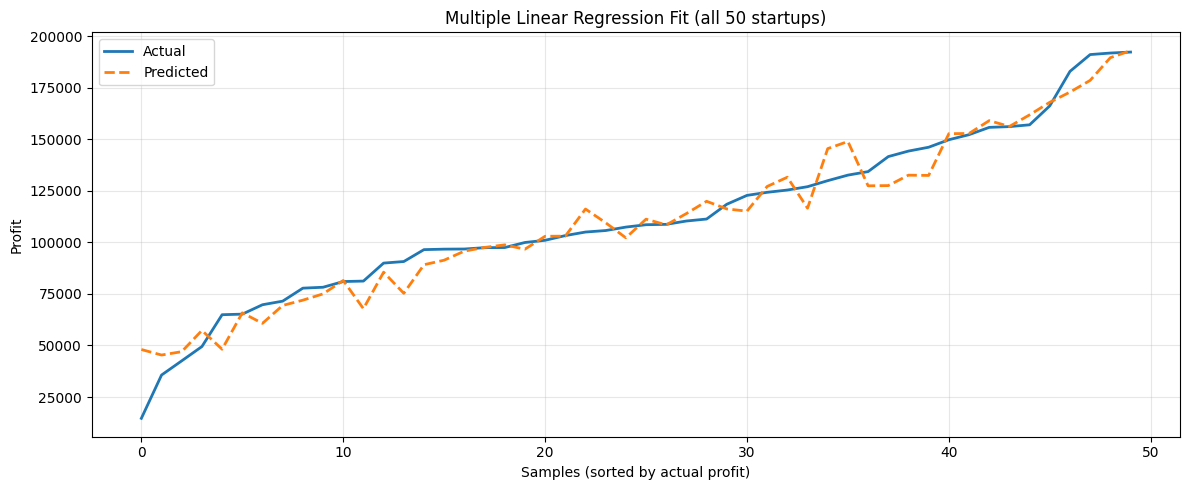

In [ ]:
y_all_pred = model.predict(X)
order = np.argsort(y.values)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.values[order], label='Actual', linewidth=2)
ax.plot(y_all_pred[order], label='Predicted', linewidth=2, linestyle='--')
ax.set_xlabel('Samples (sorted by actual profit)'); ax.set_ylabel('Profit')
ax.set_title('Multiple Linear Regression Fit (all 50 startups)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4 殘差分析

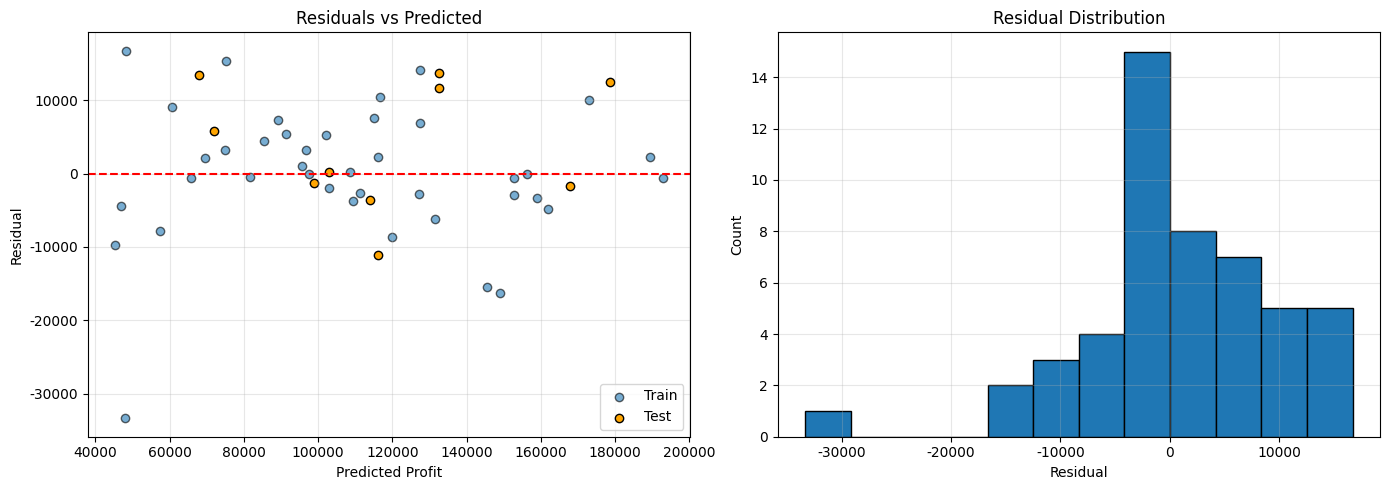

In [ ]:
residuals_train = y_train - y_pred_train
residuals_test = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_pred_train, residuals_train, alpha=0.6, label='Train', edgecolor='k')
axes[0].scatter(y_pred, residuals_test, color='orange', label='Test', edgecolor='k')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Profit'); axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predicted'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].hist(np.concatenate([residuals_train, residuals_test]), bins=12, edgecolor='k')
axes[1].set_xlabel('Residual'); axes[1].set_ylabel('Count')
axes[1].set_title('Residual Distribution'); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 回歸係數比較

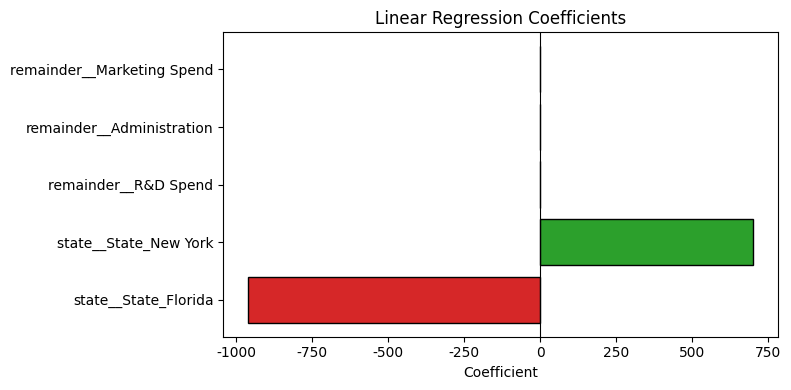

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['tab:green' if c > 0 else 'tab:red' for c in coef_df['Coefficient']]
ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='k')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Linear Regression Coefficients')
ax.set_xlabel('Coefficient')
plt.tight_layout()
plt.show()

## 7. 用模型預測新資料

In [ ]:
new_company = pd.DataFrame({
    'R&D Spend': [100000],
    'Administration': [120000],
    'Marketing Spend': [300000],
    'State': ['California']
})
print(f'預測 Profit：{model.predict(new_company)[0]:,.2f}')

預測 Profit：134,830.05


## 結論
- `R&D Spend` 與 `Profit` 相關性最高，是影響利潤最主要的因素。
- `Administration` 與 `State` 的影響相對很小。
- 模型在測試集上的 R² 接近 0.93，代表多元線性回歸能解釋大部分的利潤變異。